In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn import preprocessing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import recall_score, accuracy_score, confusion_matrix, precision_score, ConfusionMatrixDisplay
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings("ignore")

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/adult-income-prediction-dataset/adult.csv


IMPORT DATASET

In [2]:
df = pd.read_csv("/kaggle/input/adult-income-prediction-dataset/adult.csv")
df.head()

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


Let's check dataset dimensions, variable types, and basic statistics.

In [3]:
print("Shape:", df.shape)
print("\nColumns:", list(df.columns))

df.info()
df.describe()

Shape: (32561, 15)

Columns: ['age', 'workclass', 'fnlwgt', 'education', 'education.num', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'capital.gain', 'capital.loss', 'hours.per.week', 'native.country', 'income']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32561 entries, 0 to 32560
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32561 non-null  int64 
 1   workclass       32561 non-null  object
 2   fnlwgt          32561 non-null  int64 
 3   education       32561 non-null  object
 4   education.num   32561 non-null  int64 
 5   marital.status  32561 non-null  object
 6   occupation      32561 non-null  object
 7   relationship    32561 non-null  object
 8   race            32561 non-null  object
 9   sex             32561 non-null  object
 10  capital.gain    32561 non-null  int64 
 11  capital.loss    32561 non-null  int64 
 12  hours.per.week  32561 non-null  int64 


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week
count,32561.000000,3.256100e+04,32561.000000,32561.000000,32561.000000,32561.000000
mean,38.581647,1.897784e+05,10.080679,1077.648844,87.303830,40.437456
std,13.640433,1.055500e+05,2.572720,7385.292085,402.960219,12.347429
min,17.000000,1.228500e+04,1.000000,0.000000,0.000000,1.000000
25%,28.000000,1.178270e+05,9.000000,0.000000,0.000000,40.000000
50%,37.000000,1.783560e+05,10.000000,0.000000,0.000000,40.000000
75%,48.000000,2.370510e+05,12.000000,0.000000,0.000000,45.000000
max,90.000000,1.484705e+06,16.000000,99999.000000,4356.000000,99.000000


Check if there are any missing values in the dataset.

In [4]:
df.isna().sum()

age               0
workclass         0
fnlwgt            0
education         0
education.num     0
marital.status    0
occupation        0
relationship      0
race              0
sex               0
capital.gain      0
capital.loss      0
hours.per.week    0
native.country    0
income            0
dtype: int64

We separate numerical and categorical features to better understand the data structure.

In [5]:
numeric_col = df.select_dtypes(include='number').columns.tolist()
categorical_col = df.select_dtypes(include='object').columns.tolist()

print("Numerical columns:", numeric_col)
print("Categorical columns:", categorical_col)

Numerical columns: ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
Categorical columns: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country', 'income']


Let's explore how each numerical variable is distributed.

DATA VISUALISATION

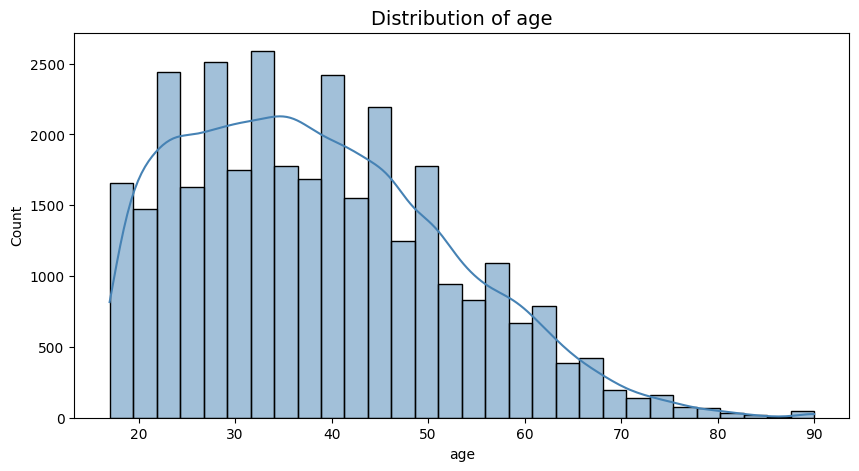

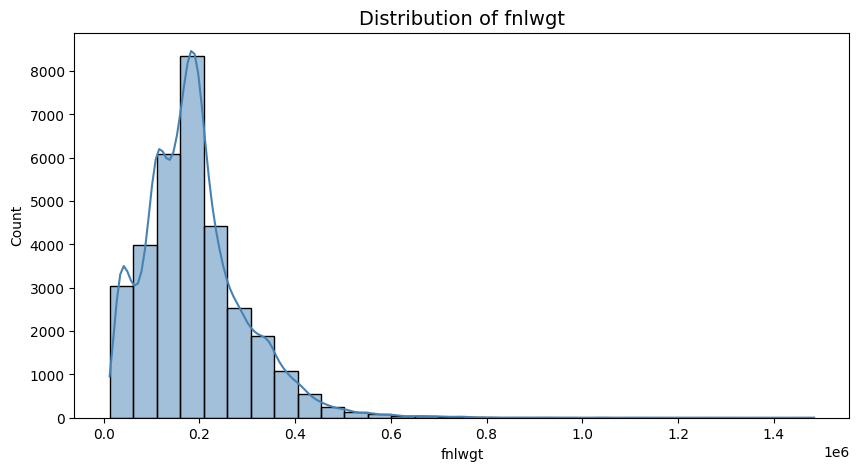

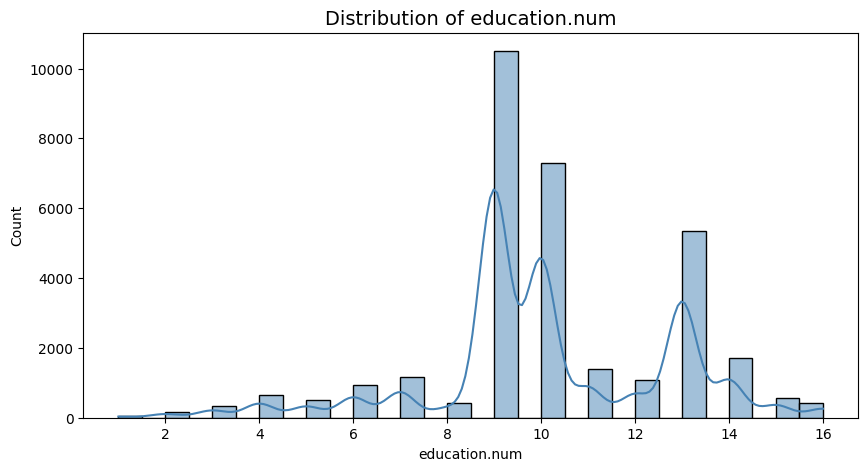

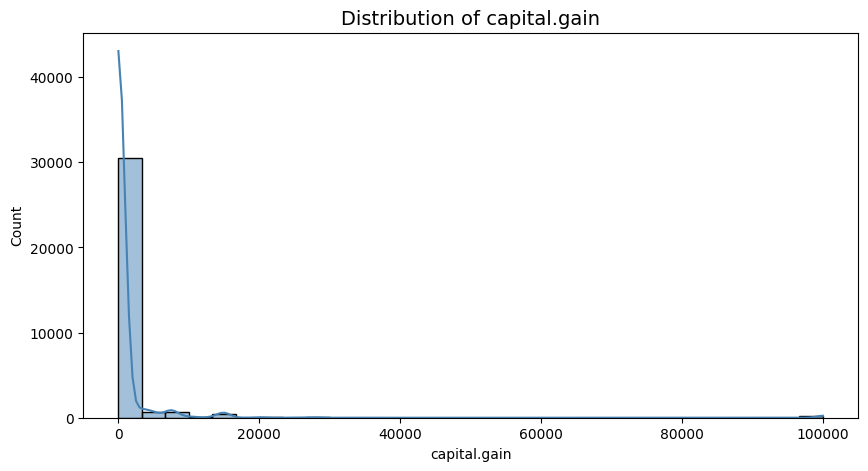

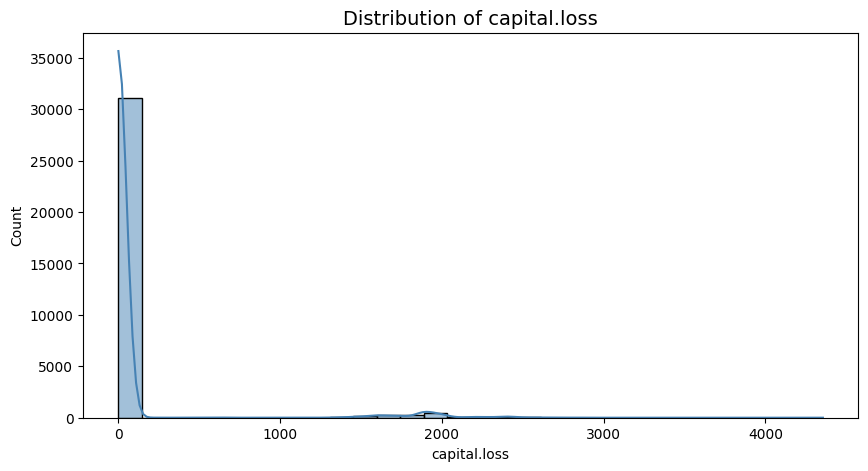

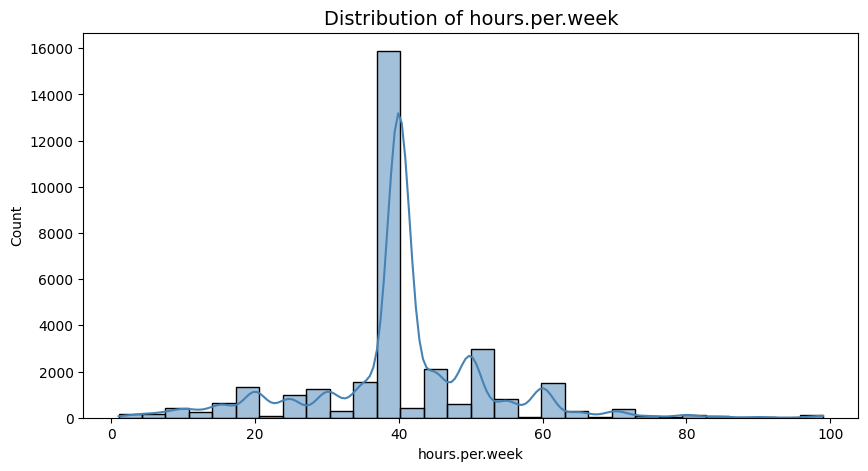

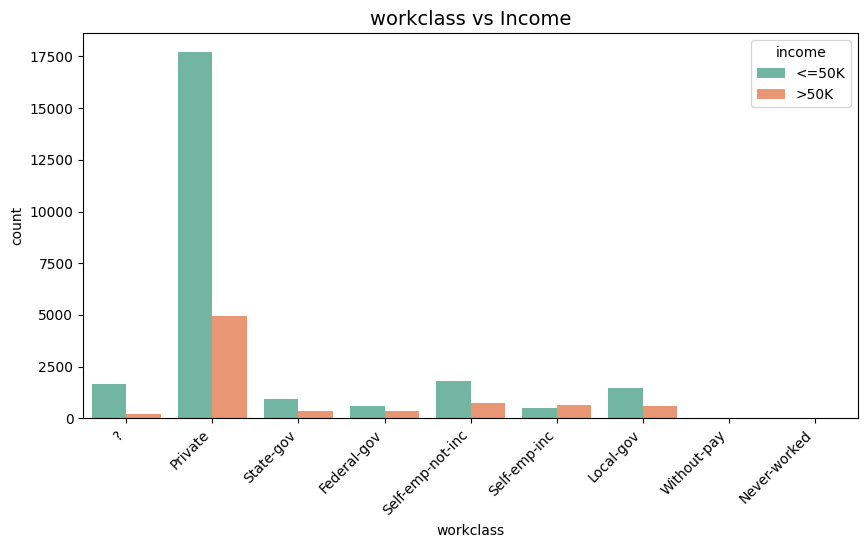

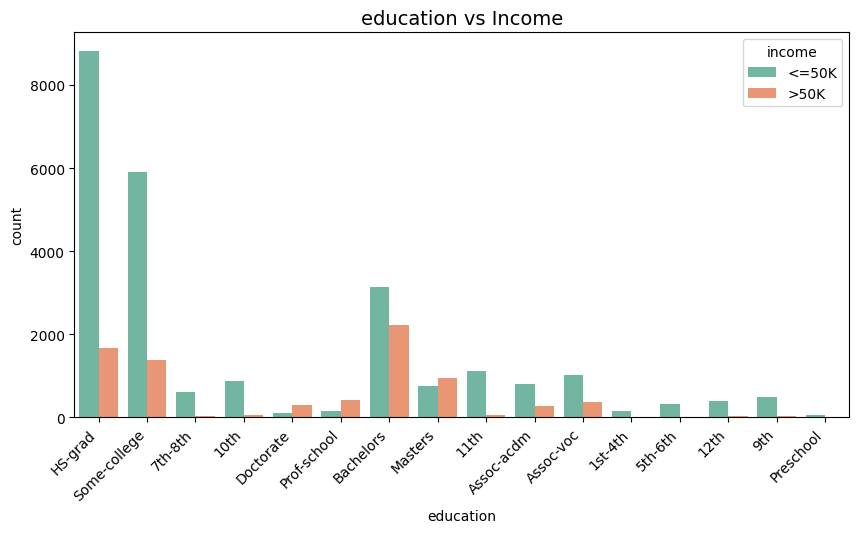

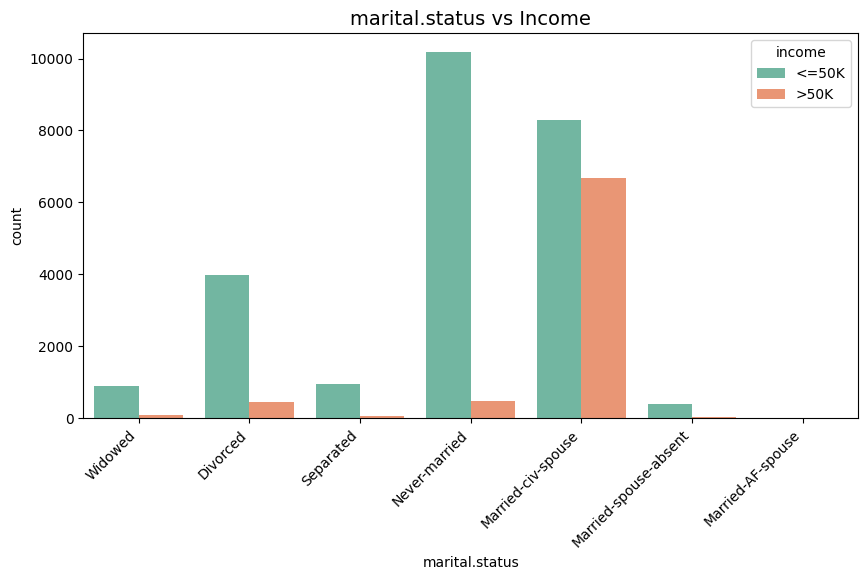

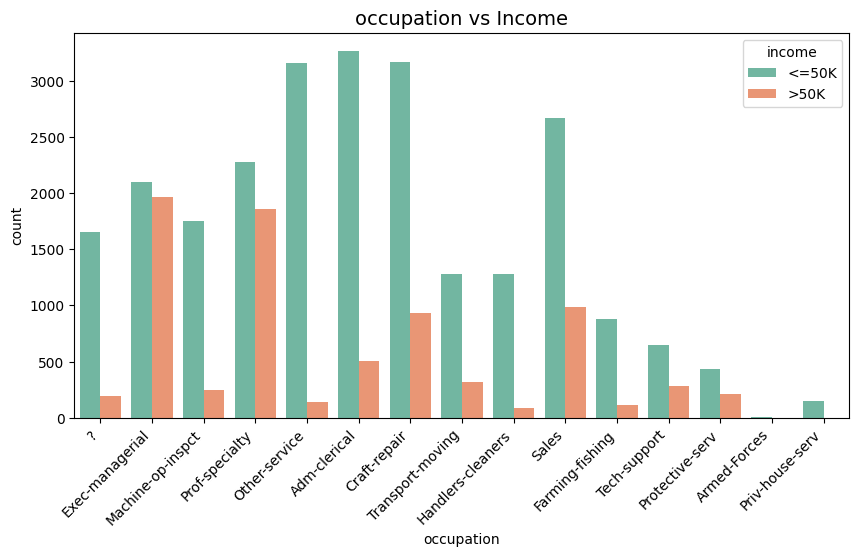

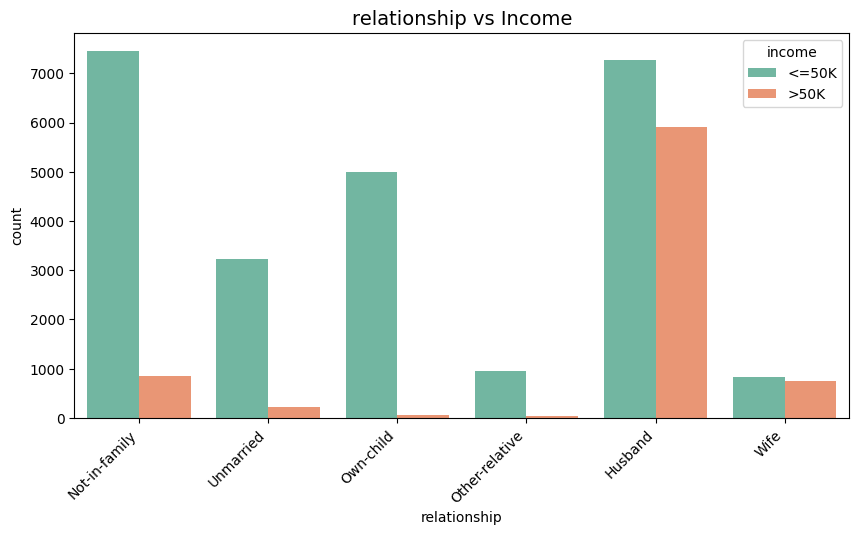

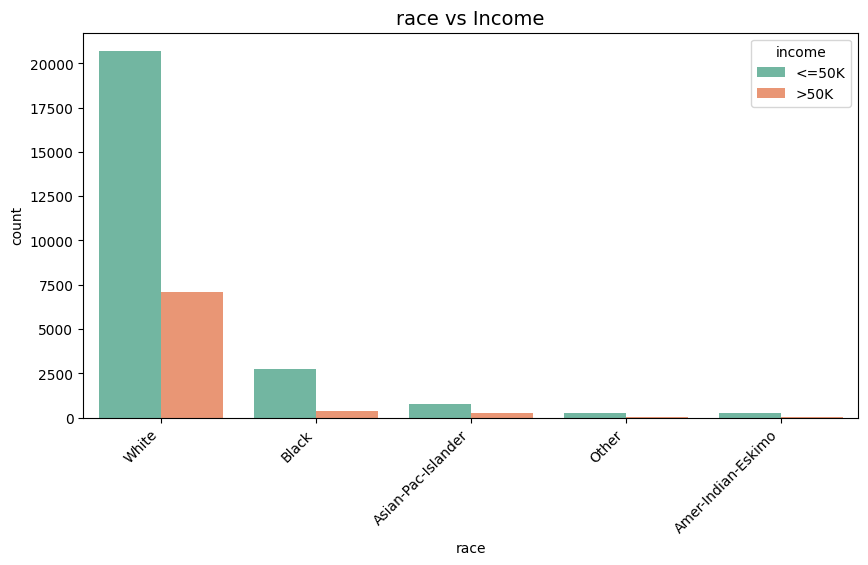

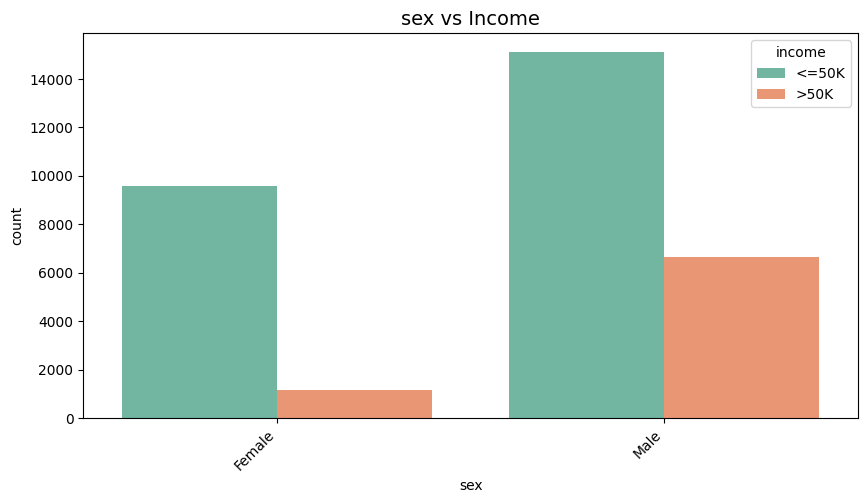

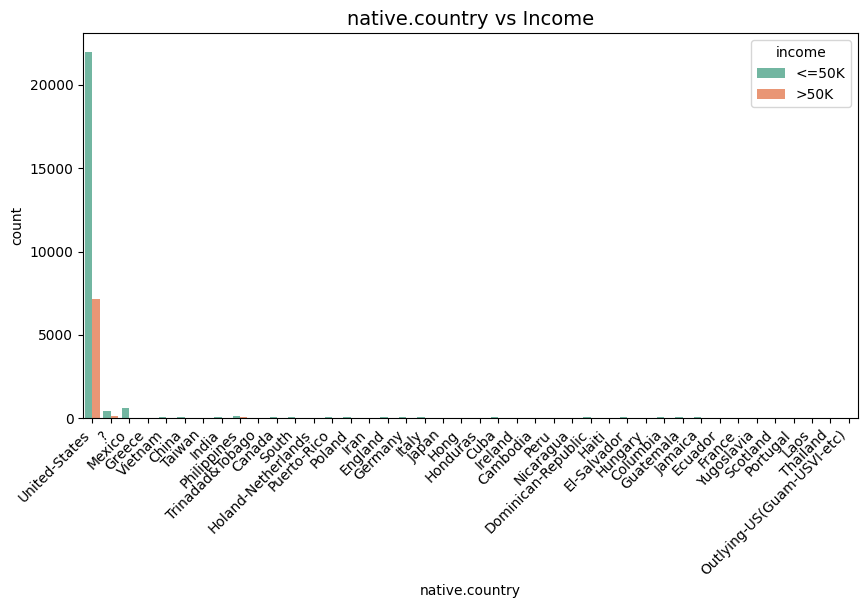

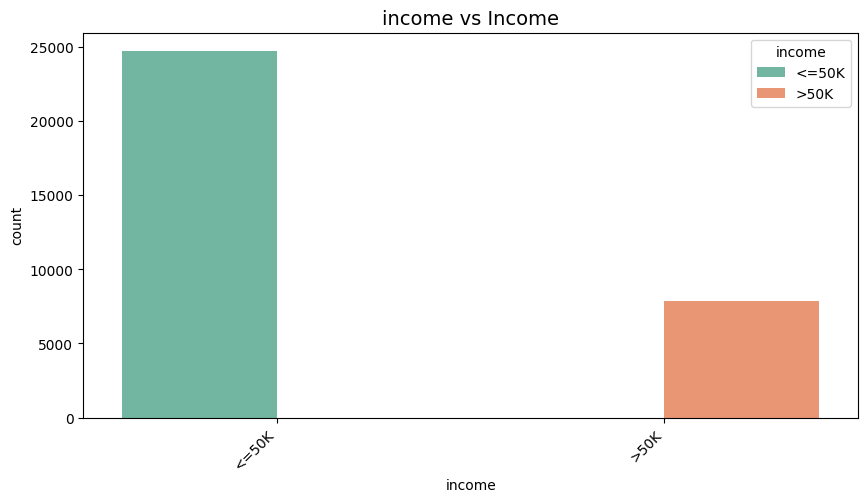

In [6]:
for col in numeric_col:
    plt.figure(figsize=(10, 5))
    sns.histplot(df[col], bins=30, kde=True, color="steelblue")
    plt.title(f"Distribution of {col}", fontsize=14)
    plt.show()

for col in categorical_col:
    plt.figure(figsize=(10, 5))
    sns.countplot(data=df, x=col, hue="income", palette="Set2")
    plt.title(f"{col} vs Income", fontsize=14)
    plt.xticks(rotation=45, ha="right")
    plt.show()

Let's see how each categorical variable relates to the target variable `income`. We select the most relevant features and normalize them before training the model.

ML IMPLEMENTING

In [7]:
X = df[["age", "fnlwgt", "education.num", "capital.gain", "capital.loss", "hours.per.week"]]
y = df["income"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


We train a Logistic Regression model and make predictions.

In [8]:
clf = LogisticRegression(random_state=42, max_iter=32561)
clf.fit(X_train, y_train)

y_pred = clf.predict(X_test)
y_proba = clf.predict_proba(X_test)[:, 1]


We adjust the decision threshold to 0.6 to improve precision and evaluate performance metrics.

In [9]:
y_pred = [1 if p > 0.6 else 0 for p in y_proba]
y_test_bin = y_test.map({">50K":1, "<=50K":0})

recall = recall_score(y_test_bin, y_pred)
precision = precision_score(y_test_bin, y_pred)
accuracy = accuracy_score(y_test_bin, y_pred)

print(f"Recall: {recall:.3f}")
print(f"Precision: {precision:.3f}")
print(f"Accuracy: {accuracy:.3f}")


Recall: 0.300
Precision: 0.793
Accuracy: 0.816


Let's visualize correct and incorrect predictions.

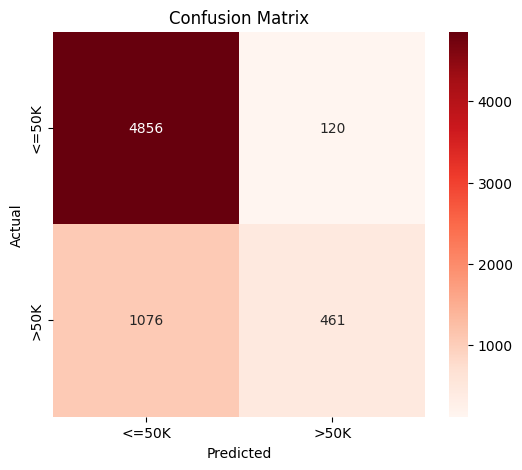

In [10]:
cm = confusion_matrix(y_test_bin, y_pred)
labels = ["<=50K", ">50K"]

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Reds", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()


Let's visualize the probability distribution for predicting income >50K.

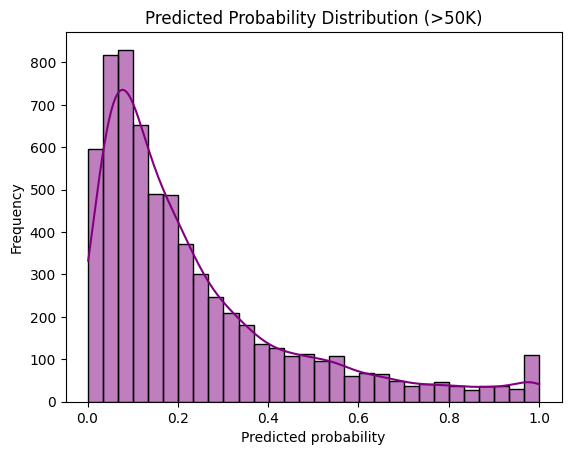

In [11]:
sns.histplot(y_proba, bins=30, kde=True, color="purple")
plt.title("Predicted Probability Distribution (>50K)")
plt.xlabel("Predicted probability")
plt.ylabel("Frequency")
plt.show()


Conclusion

The Logistic Regression model achieves an **accuracy of 81,6%** on the test set.  
This is a solid baseline for income classification.

 I am a beginner in data science and machine learning.  
This notebook is my first attempt at exploring and modeling the Adult Income dataset.  
 Any feedback, suggestions, or tips to improve my code, visualizations, or modeling approach are **highly appreciated**!  

I am eager to learn and improve, so please feel free to share your advice.